# Medellin SIC Clustering from H1 Persistence Landscapes

This notebook replicates `cluster_us_city_persistence_landscapes_pca_space.ipynb` for `processed_data/medellin_sit`.

Differences from the US-city notebook:
- no `gridiron`/`cul_de_sac` ground-truth comparison;
- only polygons with more than 10 H1 persistence-diagram points are clustered;
- both average-linkage hierarchical clustering and k-means are explored;
- cluster counts are inferred from unsupervised diagnostics, including elbow curves and silhouette scores;
- Medellin SIC polygons and OSMnx streets are mapped by cluster, with clusterless areas in gray.


In [1]:
from pathlib import Path
import json
import os
import re
import sys
import warnings

# Keep matplotlib/IPython caches inside writable locations when running from a sandboxed environment.
os.environ.setdefault('MPLCONFIGDIR', '/tmp/mplconfig')
os.environ.setdefault('IPYTHONDIR', '/tmp/ipython')
os.environ.setdefault('LOKY_MAX_CPU_COUNT', '8')

import numpy as np
import pandas as pd
import matplotlib
if 'ipykernel' not in sys.modules:
    matplotlib.use('Agg')
import matplotlib.pyplot as plt
import seaborn as sns

from pandas.errors import EmptyDataError
from scipy.cluster.hierarchy import linkage, dendrogram, fcluster
from scipy.spatial.distance import pdist, squareform
from scipy.stats import skew

from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import normalize

from IPython.display import display

warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid', context='notebook')


## 1. Configure Paths


In [2]:
def find_levelset_root(start=Path.cwd()) -> Path:
    for candidate in [start.resolve(), *start.resolve().parents]:
        if (candidate / 'processed_data' / 'medellin_sit').exists():
            return candidate
        nested = candidate / 'levelset_urban_ph'
        if (nested / 'processed_data' / 'medellin_sit').exists():
            return nested
    raise FileNotFoundError(f'Could not find levelset_urban_ph from {start.resolve()}')

PROJECT_ROOT = find_levelset_root()
DATA_DIR = PROJECT_ROOT / 'processed_data' / 'medellin_sit'
SHAPEFILE = PROJECT_ROOT / 'labeled_data' / 'medellin_polygons' / 'shape' / 'AMVA_EOD_2017_poligonos.shp'
OUTPUT_DIR = PROJECT_ROOT / 'notebooks_clustering' / 'clustering_medellin'
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

MIN_H1_POINTS = 10
RANDOM_STATE = 42
MAX_K = 12

print('Project root:', PROJECT_ROOT)
print('Processed data:', DATA_DIR)
print('Output directory:', OUTPUT_DIR)


Project root: /Users/gregorioperez/Documents/Maestria/Investigacion/levelset_urban
Processed data: /Users/gregorioperez/Documents/Maestria/Investigacion/levelset_urban/processed_data/medellin_sit
Output directory: /Users/gregorioperez/Documents/Maestria/Investigacion/levelset_urban/notebooks_clustering/clustering_medellin


## 2. Load Medellin SIC Persistence Outputs


In [3]:
POLYGON_RE = re.compile(r'^polygon_(\d+)$')

def polygon_number(name: str) -> int | None:
    match = POLYGON_RE.match(name)
    return int(match.group(1)) if match else None

def polygon_sort_key(path: Path):
    number = polygon_number(path.name)
    return (number is None, number if number is not None else path.name)

def load_json(path: Path) -> dict:
    if not path.exists():
        return {}
    with path.open() as f:
        return json.load(f)

def read_h1_pairs(path: Path) -> np.ndarray:
    if not path.exists() or path.stat().st_size == 0:
        return np.empty((0, 2), dtype=float)
    try:
        df = pd.read_csv(path, header=None)
    except EmptyDataError:
        return np.empty((0, 2), dtype=float)
    arr = df.iloc[:, :2].apply(pd.to_numeric, errors='coerce').dropna().to_numpy(float)
    arr = arr[np.isfinite(arr).all(axis=1)]
    arr = arr[arr[:, 1] >= arr[:, 0]]
    return arr

def read_landscape(path: Path) -> tuple[np.ndarray, np.ndarray, bool]:
    with np.load(path) as z:
        landscape = z['landscape_values'].astype(float)
        x_grid = z['x_grid'].astype(float)
        empty = bool(z['empty']) if 'empty' in z.files else False
    return landscape, x_grid, empty

def diagram_summary_features(diagram: np.ndarray) -> dict:
    if diagram.size == 0:
        return {
            'pd_count': 0, 'pd_lifetime_mean': 0, 'pd_lifetime_std': 0, 'pd_lifetime_max': 0,
            'pd_lifetime_sum': 0, 'pd_lifetime_q25': 0, 'pd_lifetime_q50': 0, 'pd_lifetime_q75': 0,
            'pd_birth_mean': 0, 'pd_death_mean': 0, 'pd_lifetime_skew': 0,
        }
    birth = diagram[:, 0]
    death = diagram[:, 1]
    lifetime = death - birth
    return {
        'pd_count': len(lifetime),
        'pd_lifetime_mean': float(np.mean(lifetime)),
        'pd_lifetime_std': float(np.std(lifetime)),
        'pd_lifetime_max': float(np.max(lifetime)),
        'pd_lifetime_sum': float(np.sum(lifetime)),
        'pd_lifetime_q25': float(np.quantile(lifetime, 0.25)),
        'pd_lifetime_q50': float(np.quantile(lifetime, 0.50)),
        'pd_lifetime_q75': float(np.quantile(lifetime, 0.75)),
        'pd_birth_mean': float(np.mean(birth)),
        'pd_death_mean': float(np.mean(death)),
        'pd_lifetime_skew': float(skew(lifetime)) if len(lifetime) > 2 else 0.0,
    }

status_records = []
included_records = []
landscape_arrays = []
x_grids = []
diagrams = []

for sample_dir in sorted([p for p in DATA_DIR.iterdir() if p.is_dir()], key=polygon_sort_key):
    metadata = load_json(sample_dir / 'metadata.json')
    status = load_json(sample_dir / 'status.json')
    pnum = polygon_number(sample_dir.name)
    source_row_index = metadata.get('source_row_index')
    if source_row_index is None and pnum is not None:
        source_row_index = pnum - 1

    diagram_path = sample_dir / 'h1_pairs.csv'
    landscape_path = sample_dir / 'persistence_landscape_h1.npz'
    diagram = read_h1_pairs(diagram_path)

    base_record = {
        'polygon_id': sample_dir.name,
        'polygon_number': pnum,
        'source_row_index': source_row_index,
        'sit_2017': str(metadata.get('properties', {}).get('SIT_2017', '')),
        'pipeline_status': status.get('status', 'unknown'),
        'has_h1_pairs': diagram_path.exists(),
        'has_landscape': landscape_path.exists(),
        'n_h1_pairs': len(diagram),
    }

    include = diagram_path.exists() and landscape_path.exists() and len(diagram) > MIN_H1_POINTS
    if not include:
        if not diagram_path.exists() or not landscape_path.exists():
            base_record['clusterless_reason'] = 'missing_outputs'
        elif len(diagram) <= MIN_H1_POINTS:
            base_record['clusterless_reason'] = 'too_few_h1_pairs'
        else:
            base_record['clusterless_reason'] = 'not_clustered'
        status_records.append(base_record)
        continue

    try:
        landscape, x_grid, landscape_empty = read_landscape(landscape_path)
    except Exception as exc:
        base_record['clusterless_reason'] = f'landscape_read_error: {exc}'
        status_records.append(base_record)
        continue

    if landscape_empty or landscape.size == 0 or x_grid.size == 0:
        base_record['clusterless_reason'] = 'empty_landscape'
        status_records.append(base_record)
        continue

    record = {
        **base_record,
        'clusterless_reason': 'clustered',
        'x_min': float(np.nanmin(x_grid)),
        'x_max': float(np.nanmax(x_grid)),
        'diagram_min': float(np.nanmin(diagram[:, 0])) if len(diagram) else 0.0,
        'diagram_max': float(np.nanmax(diagram[:, 1])) if len(diagram) else 0.0,
        'n_landscape_levels': landscape.shape[0],
        'landscape_resolution': landscape.shape[1],
    }
    status_records.append(record)
    included_records.append(record)
    landscape_arrays.append(landscape)
    x_grids.append(x_grid)
    diagrams.append(diagram)

sample_status = pd.DataFrame(status_records)
meta = pd.DataFrame(included_records)

print(f'Found {len(sample_status)} polygon folders in {DATA_DIR}')
print(f'Included {len(meta)} polygons with more than {MIN_H1_POINTS} H1 pairs')
display(sample_status['clusterless_reason'].value_counts(dropna=False).rename_axis('status').reset_index(name='n_polygons'))
display(meta[['polygon_id', 'sit_2017', 'n_h1_pairs', 'x_min', 'x_max']].head())
display(meta[['n_h1_pairs', 'x_max']].describe())


Found 513 polygon folders in /Users/gregorioperez/Documents/Maestria/Investigacion/levelset_urban/processed_data/medellin_sit
Included 340 polygons with more than 10 H1 pairs


,status,n_polygons
0,clustered,340
1,too_few_h1_pairs,167
2,missing_outputs,6


,polygon_id,sit_2017,n_h1_pairs,x_min,x_max
0,polygon_1,37,13,0.0,70.8
1,polygon_2,632,13,0.0,101.6
2,polygon_3,468,65,0.0,87.9
3,polygon_4,460,41,0.0,94.6
4,polygon_5,469,95,0.0,84.8


,n_h1_pairs,x_max
count,340.000000,340.000000
mean,38.823529,108.586765
std,26.754726,38.788010
min,11.000000,36.400000
25%,20.000000,77.700000
50%,32.000000,101.950000
75%,51.000000,132.250000
max,177.000000,200.000000


## 3. Build Comparable Landscape Features


In [4]:
COMMON_RESOLUTION = 500
N_LEVELS = 50
common_grid = np.linspace(0.0, 1.0, COMMON_RESOLUTION)

def normalize_resample_landscape(landscape: np.ndarray, x_grid: np.ndarray, n_levels=N_LEVELS) -> np.ndarray:
    x = np.asarray(x_grid, dtype=float)
    y = np.asarray(landscape, dtype=float)
    if x.max() > x.min():
        x_norm = (x - x.min()) / (x.max() - x.min())
    else:
        x_norm = np.linspace(0.0, 1.0, len(x))

    levels = []
    for k in range(min(n_levels, y.shape[0])):
        levels.append(np.interp(common_grid, x_norm, y[k], left=0.0, right=0.0))

    while len(levels) < n_levels:
        levels.append(np.zeros_like(common_grid))

    # Divide amplitudes by the filtration span so districts with different absolute scales remain comparable.
    span = max(float(x.max() - x.min()), 1e-12)
    return (np.vstack(levels) / span).ravel()

X_landscape = np.vstack([
    normalize_resample_landscape(landscape, x_grid)
    for landscape, x_grid in zip(landscape_arrays, x_grids)
])
X = normalize(np.nan_to_num(X_landscape), norm='l2')

diagram_features = pd.DataFrame([diagram_summary_features(d) for d in diagrams])
meta_features = pd.concat([meta.reset_index(drop=True), diagram_features], axis=1)

print('Landscape feature matrix:', X_landscape.shape)
print('L2-normalized matrix:', X.shape)
display(meta_features.head())


Landscape feature matrix: (340, 25000)
L2-normalized matrix: (340, 25000)


,polygon_id,polygon_number,source_row_index,sit_2017,pipeline_status,has_h1_pairs,has_landscape,n_h1_pairs,clusterless_reason,x_min,...,pd_lifetime_mean,pd_lifetime_std,pd_lifetime_max,pd_lifetime_sum,pd_lifetime_q25,pd_lifetime_q50,pd_lifetime_q75,pd_birth_mean,pd_death_mean,pd_lifetime_skew
0,polygon_1,1,0,37,complete,True,True,13,clustered,0.0,...,35.630769,17.179253,70.8,463.2,24.3,41.8,45.90,1.192308,36.823077,-0.015855
1,polygon_2,2,1,632,complete,True,True,13,clustered,0.0,...,20.253846,27.610885,100.9,263.3,3.0,12.3,15.90,21.423077,41.676923,1.987375
2,polygon_3,3,2,468,complete,True,True,65,clustered,0.0,...,6.752308,7.620864,36.2,438.9,1.8,4.1,6.60,10.464615,17.216923,2.095443
3,polygon_4,4,3,460,complete,True,True,41,clustered,0.0,...,9.395122,10.778387,50.7,385.2,2.6,5.3,11.10,11.092683,20.487805,2.237492
4,polygon_5,5,4,469,complete,True,True,95,clustered,0.0,...,7.854737,11.600706,74.6,746.2,2.1,3.3,7.95,12.460000,20.314737,3.192766


## 4. PCA Representation for Clustering


In [5]:
PCA_VARIANCE_TARGET = 0.90
MAX_PCA_COMPONENTS = 20

n_pca_components = min(MAX_PCA_COMPONENTS, X.shape[0] - 1, X.shape[1])
pca = PCA(n_components=n_pca_components, random_state=RANDOM_STATE)
X_pca_full = pca.fit_transform(X)
explained = np.cumsum(pca.explained_variance_ratio_)
n_cluster_components = int(np.searchsorted(explained, PCA_VARIANCE_TARGET) + 1)
n_cluster_components = max(2, min(n_cluster_components, n_pca_components))
X_cluster = X_pca_full[:, :n_cluster_components]
X_pca2 = X_pca_full[:, :2]

print(f'PCA components fitted: {n_pca_components}')
print(f'PCA components used for clustering: {n_cluster_components}')
print(f'Explained variance used for clustering: {explained[n_cluster_components - 1]:.3f}')
display(pd.DataFrame({
    'component': np.arange(1, n_pca_components + 1),
    'explained_variance_ratio': pca.explained_variance_ratio_,
    'cumulative_explained_variance': explained,
}).head(10))


PCA components fitted: 20
PCA components used for clustering: 18
Explained variance used for clustering: 0.903


,component,explained_variance_ratio,cumulative_explained_variance
0,1,0.299422,0.299422
1,2,0.152917,0.452340
2,3,0.113661,0.566000
3,4,0.074635,0.640635
4,5,0.055232,0.695867
5,6,0.035333,0.731200
6,7,0.032303,0.763503
7,8,0.027029,0.790532
8,9,0.019316,0.809849
9,10,0.016345,0.826194


## 5. Infer Cluster Counts


Hierarchical elbow k: 5; silhouette-best k: 2; selected k: 5
K-means elbow k: 6; silhouette-best k: 3; selected k: 6


,k,n_clusters_observed,within_cluster_ss,silhouette
0,2,2,112.184550,0.277938
1,3,3,110.741406,0.189850
2,4,4,110.059190,0.150147
3,5,5,108.433247,0.146067
4,6,6,78.837910,0.201133
5,7,7,78.332522,0.192385
6,8,8,77.558479,0.191126
7,9,9,65.851323,0.207323
8,10,10,64.857408,0.206014
9,11,11,63.835515,0.191184


,k,n_clusters_observed,inertia,silhouette
0,2,2,90.470658,0.247158
1,3,3,74.963743,0.247697
2,4,4,65.704055,0.222115
3,5,5,58.857448,0.224289
4,6,6,53.417287,0.232819
5,7,7,49.167204,0.220130
6,8,8,45.576318,0.222577
7,9,9,42.556093,0.224991
8,10,10,40.661585,0.225810
9,11,11,39.110516,0.219719


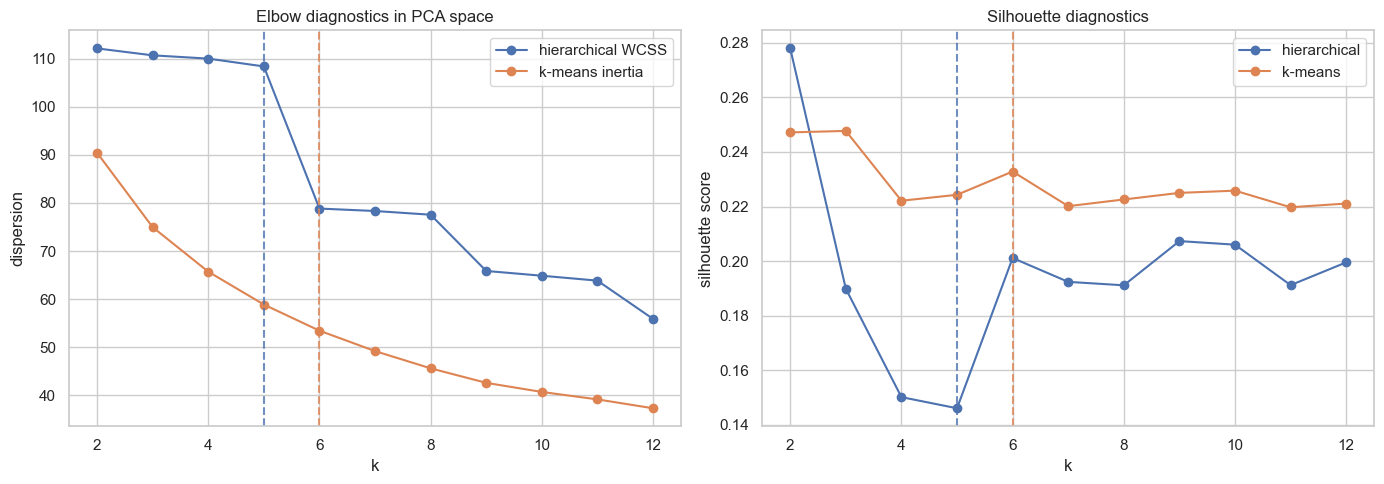

In [6]:
def candidate_k_values(n_samples: int, max_k: int = MAX_K) -> list[int]:
    return list(range(2, min(max_k, n_samples - 1) + 1))

def make_contiguous_labels(labels: np.ndarray) -> np.ndarray:
    labels = np.asarray(labels)
    mapping = {old: new for new, old in enumerate(sorted(pd.unique(labels)))}
    return np.array([mapping[x] for x in labels], dtype=int)

def safe_silhouette(data: np.ndarray, labels: np.ndarray, metric: str = 'euclidean') -> float:
    n_labels = len(np.unique(labels))
    if n_labels < 2 or n_labels >= len(labels):
        return np.nan
    return float(silhouette_score(data, labels, metric=metric))

def cluster_wcss(features: np.ndarray, labels: np.ndarray) -> float:
    total = 0.0
    for label in np.unique(labels):
        group = features[labels == label]
        center = group.mean(axis=0)
        total += float(((group - center) ** 2).sum())
    return total

def elbow_k(k_values, values) -> int:
    k = np.asarray(k_values, dtype=float)
    y = np.asarray(values, dtype=float)
    valid = np.isfinite(k) & np.isfinite(y)
    k = k[valid]
    y = y[valid]
    if len(k) < 3 or np.allclose(y, y[0]):
        return int(k[0])
    x_norm = (k - k.min()) / max(k.max() - k.min(), 1e-12)
    y_norm = (y - y.min()) / max(y.max() - y.min(), 1e-12)
    points = np.column_stack([x_norm, y_norm])
    start = points[0]
    end = points[-1]
    line = end - start
    line_norm = np.linalg.norm(line)
    if line_norm == 0:
        return int(k[0])
    deltas = points - start
    distances = np.abs(line[0] * deltas[:, 1] - line[1] * deltas[:, 0]) / line_norm
    return int(k[int(np.argmax(distances))])

def best_silhouette_k(diagnostics: pd.DataFrame) -> int | None:
    valid = diagnostics.dropna(subset=['silhouette'])
    if valid.empty:
        return None
    return int(valid.loc[valid['silhouette'].idxmax(), 'k'])

candidate_ks = candidate_k_values(len(meta_features), MAX_K)
condensed_pca_dist = pdist(X_cluster, metric='euclidean')
D_pca = squareform(condensed_pca_dist)
Z = linkage(condensed_pca_dist, method='average')

hierarchical_rows = []
for k in candidate_ks:
    labels = make_contiguous_labels(fcluster(Z, t=k, criterion='maxclust'))
    hierarchical_rows.append({
        'k': k,
        'n_clusters_observed': len(np.unique(labels)),
        'within_cluster_ss': cluster_wcss(X_cluster, labels),
        'silhouette': safe_silhouette(D_pca, labels, metric='precomputed'),
    })
hierarchical_diagnostics = pd.DataFrame(hierarchical_rows)

kmeans_rows = []
for k in candidate_ks:
    model = KMeans(n_clusters=k, n_init=50, random_state=RANDOM_STATE)
    labels = model.fit_predict(X_cluster)
    kmeans_rows.append({
        'k': k,
        'n_clusters_observed': len(np.unique(labels)),
        'inertia': float(model.inertia_),
        'silhouette': safe_silhouette(X_cluster, labels, metric='euclidean'),
    })
kmeans_diagnostics = pd.DataFrame(kmeans_rows)

hierarchical_elbow_k = elbow_k(hierarchical_diagnostics['k'], hierarchical_diagnostics['within_cluster_ss'])
hierarchical_silhouette_k = best_silhouette_k(hierarchical_diagnostics)
kmeans_elbow_k = elbow_k(kmeans_diagnostics['k'], kmeans_diagnostics['inertia'])
kmeans_silhouette_k = best_silhouette_k(kmeans_diagnostics)

# Optional manual overrides after inspecting the diagnostics. Leave as None for inferred cluster counts.
OVERRIDE_HIERARCHICAL_K = None
OVERRIDE_KMEANS_K = None
SELECTED_HIERARCHICAL_K = OVERRIDE_HIERARCHICAL_K or hierarchical_elbow_k
SELECTED_KMEANS_K = OVERRIDE_KMEANS_K or kmeans_elbow_k

print(f'Hierarchical elbow k: {hierarchical_elbow_k}; silhouette-best k: {hierarchical_silhouette_k}; selected k: {SELECTED_HIERARCHICAL_K}')
print(f'K-means elbow k: {kmeans_elbow_k}; silhouette-best k: {kmeans_silhouette_k}; selected k: {SELECTED_KMEANS_K}')
display(hierarchical_diagnostics)
display(kmeans_diagnostics)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].plot(hierarchical_diagnostics['k'], hierarchical_diagnostics['within_cluster_ss'], marker='o', label='hierarchical WCSS')
axes[0].plot(kmeans_diagnostics['k'], kmeans_diagnostics['inertia'], marker='o', label='k-means inertia')
axes[0].axvline(SELECTED_HIERARCHICAL_K, color='C0', linestyle='--', alpha=0.8)
axes[0].axvline(SELECTED_KMEANS_K, color='C1', linestyle='--', alpha=0.8)
axes[0].set_title('Elbow diagnostics in PCA space')
axes[0].set_xlabel('k')
axes[0].set_ylabel('dispersion')
axes[0].legend()

axes[1].plot(hierarchical_diagnostics['k'], hierarchical_diagnostics['silhouette'], marker='o', label='hierarchical')
axes[1].plot(kmeans_diagnostics['k'], kmeans_diagnostics['silhouette'], marker='o', label='k-means')
axes[1].axvline(SELECTED_HIERARCHICAL_K, color='C0', linestyle='--', alpha=0.8)
axes[1].axvline(SELECTED_KMEANS_K, color='C1', linestyle='--', alpha=0.8)
axes[1].set_title('Silhouette diagnostics')
axes[1].set_xlabel('k')
axes[1].set_ylabel('silhouette score')
axes[1].legend()

plt.tight_layout()
plt.show()


## 6. Fit Hierarchical and K-Means Clusters


In [7]:
hierarchical_labels = make_contiguous_labels(fcluster(Z, t=SELECTED_HIERARCHICAL_K, criterion='maxclust'))
kmeans_model = KMeans(n_clusters=SELECTED_KMEANS_K, n_init=100, random_state=RANDOM_STATE)
kmeans_labels = kmeans_model.fit_predict(X_cluster)

meta_features['hierarchical_cluster'] = hierarchical_labels
meta_features['kmeans_cluster'] = kmeans_labels

print('Hierarchical cluster sizes')
display(meta_features['hierarchical_cluster'].value_counts().sort_index().rename_axis('cluster').reset_index(name='n_polygons'))
print('K-means cluster sizes')
display(meta_features['kmeans_cluster'].value_counts().sort_index().rename_axis('cluster').reset_index(name='n_polygons'))
print('Cross-tabulation of the two unsupervised clusterings')
display(pd.crosstab(meta_features['hierarchical_cluster'], meta_features['kmeans_cluster']))


Hierarchical cluster sizes


,cluster,n_polygons
0,0,15
1,1,5
2,2,1
3,3,2
4,4,317


K-means cluster sizes


,cluster,n_polygons
0,0,61
1,1,53
2,2,53
3,3,19
4,4,82
5,5,72


Cross-tabulation of the two unsupervised clusterings


kmeans_cluster,0,1,2,3,4,5
hierarchical_cluster,,,,,,
0,0,0,1,14,0,0
1,0,0,1,4,0,0
2,1,0,0,0,0,0
3,0,2,0,0,0,0
4,60,51,51,1,82,72


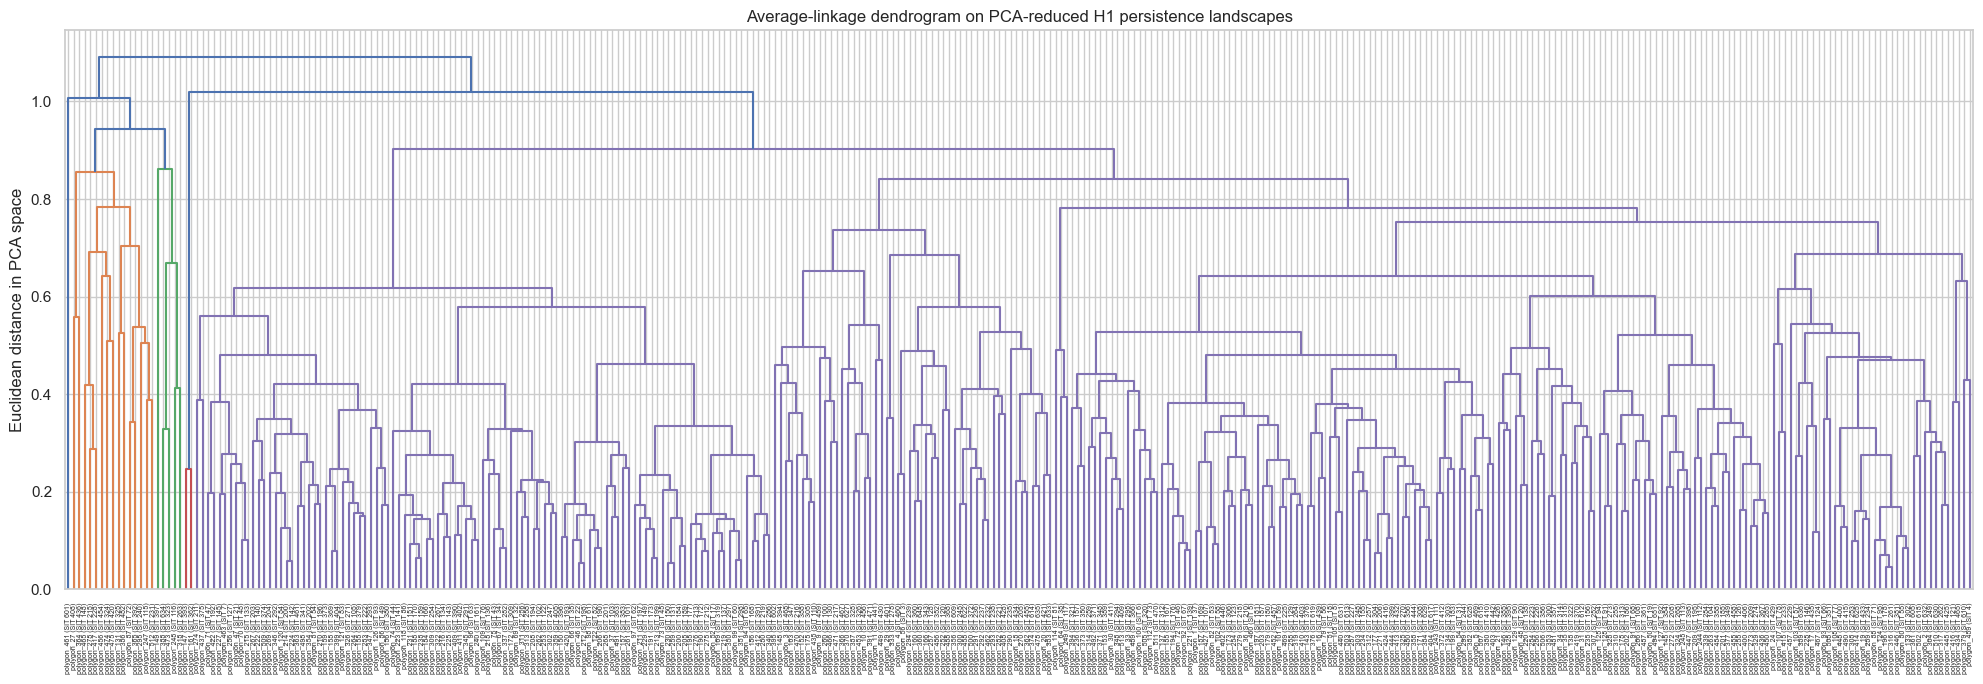

In [8]:
plt.figure(figsize=(20, 7))
leaf_labels = [f"{row.polygon_id} (SIT {row.sit_2017})" for row in meta_features.itertuples()]
dendrogram(
    Z,
    labels=leaf_labels,
    leaf_rotation=90,
    leaf_font_size=5,
    color_threshold=Z[-SELECTED_HIERARCHICAL_K + 1, 2] if SELECTED_HIERARCHICAL_K > 1 else None,
)
plt.title('Average-linkage dendrogram on PCA-reduced H1 persistence landscapes')
plt.ylabel('Euclidean distance in PCA space')
plt.tight_layout()
plt.show()


## 7. PCA and t-SNE Visualizations


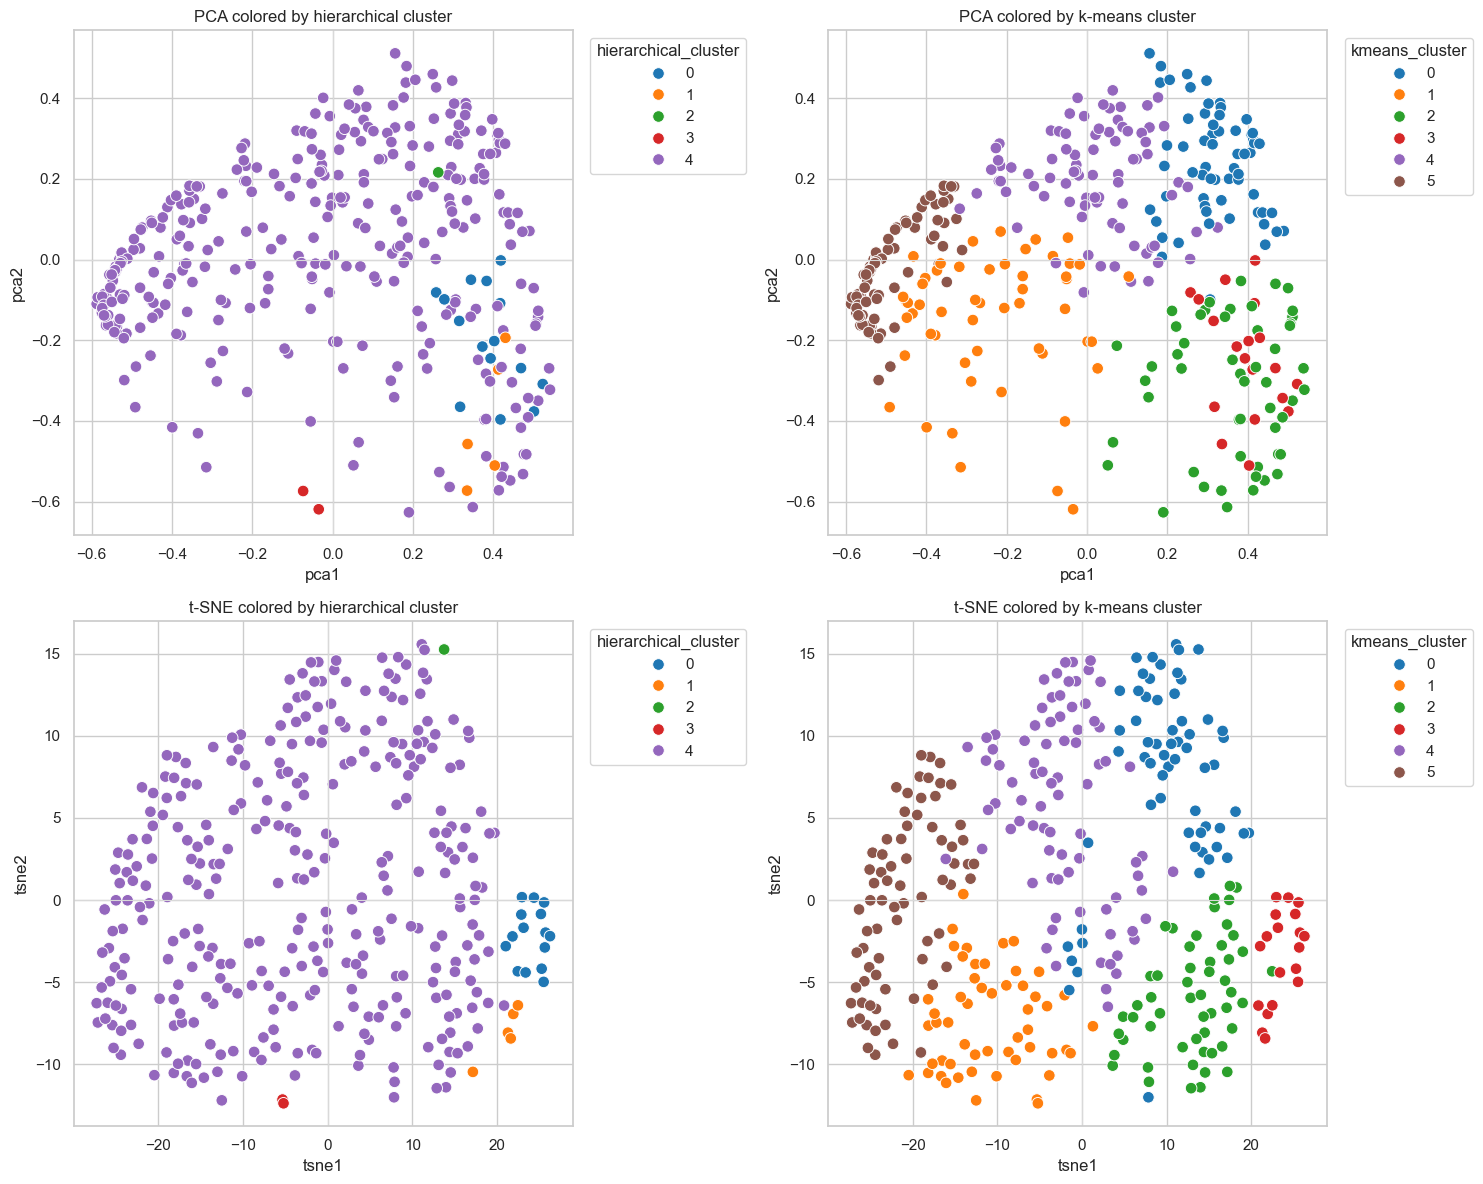

In [9]:
tsne = TSNE(
    n_components=2,
    perplexity=min(30, max(5, (len(meta_features) - 1) // 3)),
    init='pca',
    learning_rate='auto',
    random_state=RANDOM_STATE,
)
X_tsne = tsne.fit_transform(X_cluster)

viz = meta_features.copy()
viz['pca1'] = X_pca2[:, 0]
viz['pca2'] = X_pca2[:, 1]
viz['tsne1'] = X_tsne[:, 0]
viz['tsne2'] = X_tsne[:, 1]

fig, axes = plt.subplots(2, 2, figsize=(15, 12))
plot_specs = [
    ('hierarchical_cluster', 'PCA colored by hierarchical cluster', 'pca1', 'pca2'),
    ('kmeans_cluster', 'PCA colored by k-means cluster', 'pca1', 'pca2'),
    ('hierarchical_cluster', 't-SNE colored by hierarchical cluster', 'tsne1', 'tsne2'),
    ('kmeans_cluster', 't-SNE colored by k-means cluster', 'tsne1', 'tsne2'),
]
for ax, (cluster_col, title, x_col, y_col) in zip(axes.ravel(), plot_specs):
    sns.scatterplot(data=viz, x=x_col, y=y_col, hue=cluster_col, palette='tab10', s=70, ax=ax)
    ax.set_title(title)
    ax.axhline(0, color='0.85', linewidth=0.8)
    ax.axvline(0, color='0.85', linewidth=0.8)
    ax.legend(title=cluster_col, bbox_to_anchor=(1.02, 1), loc='upper left')

plt.tight_layout()
plt.show()


## 8. Cluster Summaries


hierarchical_cluster


n_h1_pairs                         x_max                  \
                          count     mean median     std count     mean median   
hierarchical_cluster                                                            
0                            15   30.667   24.0  16.893    15  159.413  165.5   
1                             5   25.800   17.0  16.239     5  177.720  188.3   
2                             1   39.000   39.0     NaN     1  105.900  105.9   
3                             2  109.500  109.5   3.536     2   95.300   95.3   
4                           317   38.968   32.0  26.729   317  105.184   99.0   

                             pd_count           ... pd_lifetime_sum           \
                         std    count     mean  ...          median      std   
hierarchical_cluster                            ...                            
0                     35.200       15   30.667  ...          273.30   90.277   
1                     28.753        5   25.800  ...          182.30  158.031   
2                        NaN        1   39.000  ...          220.80      NaN   
3                      1.414        2  109.500  ...         1973.85  185.474   
4                     36.574      317   38.968  ...          817.40  434.287   

                     pd_lifetime_q50                         pd_lifetime_q75  \
                               count    mean  median     std           count   
hierarchical_cluster                                                           
0                                 15   5.507   5.800   2.280              15   
1                                  5   7.380   7.900   4.337               5   
2                                  1   2.500   2.500     NaN               1   
3                                  2  18.325  18.325   1.308               2   
4                                317  23.791  18.550  19.100             317   

                                              
                        mean  median     std  
hierarchical_cluster                          
0                     13.595  13.225   6.491  
1                     12.895  12.300   8.099  
2                      5.500   5.500     NaN  
3                     25.575  25.575   1.874  
4                     36.600  30.825  21.955  

[5 rows x 36 columns]

kmeans_cluster


n_h1_pairs                        x_max                   \
                    count    mean median     std count     mean  median   
kmeans_cluster                                                            
0                      61  31.508   21.0  27.844    61  137.990  134.10   
1                      53  54.755   48.0  23.540    53   86.015   86.50   
2                      53  43.943   34.0  30.396    53  126.247  128.30   
3                      19  27.263   24.0  15.358    19  166.037  168.60   
4                      82  36.988   27.5  27.342    82  102.524   99.55   
5                      72  34.667   30.5  21.336    72   79.035   75.80   

                       pd_count          ... pd_lifetime_sum           \
                   std    count    mean  ...          median      std   
kmeans_cluster                           ...                            
0               37.072       61  31.508  ...          451.60  325.513   
1               20.069       53  54.755  ...         1270.50  352.497   
2               31.814       53  43.943  ...          549.30  262.468   
3               31.003       19  27.263  ...          228.50   89.300   
4               31.333       82  36.988  ...          718.45  261.877   
5               21.327       72  34.667  ...         1175.25  339.816   

               pd_lifetime_q50                        pd_lifetime_q75          \
                         count    mean median     std           count    mean   
kmeans_cluster                                                                  
0                           61  12.270  10.15   9.311              61  23.598   
1                           53  27.957  26.05  10.946              53  34.772   
2                           53  12.541   9.00  11.055              53  23.228   
3                           19   5.682   5.80   2.283              19  13.443   
4                           82  18.230  12.50  15.273              82  36.223   
5                           72  44.485  41.80  20.627              72  58.166   

                                
                median     std  
kmeans_cluster                  
0               20.725  13.789  
1               32.075  11.952  
2               19.150  16.195  
3               12.975   6.572  
4               32.538  21.557  
5               55.825  20.754  

[6 rows x 36 columns]

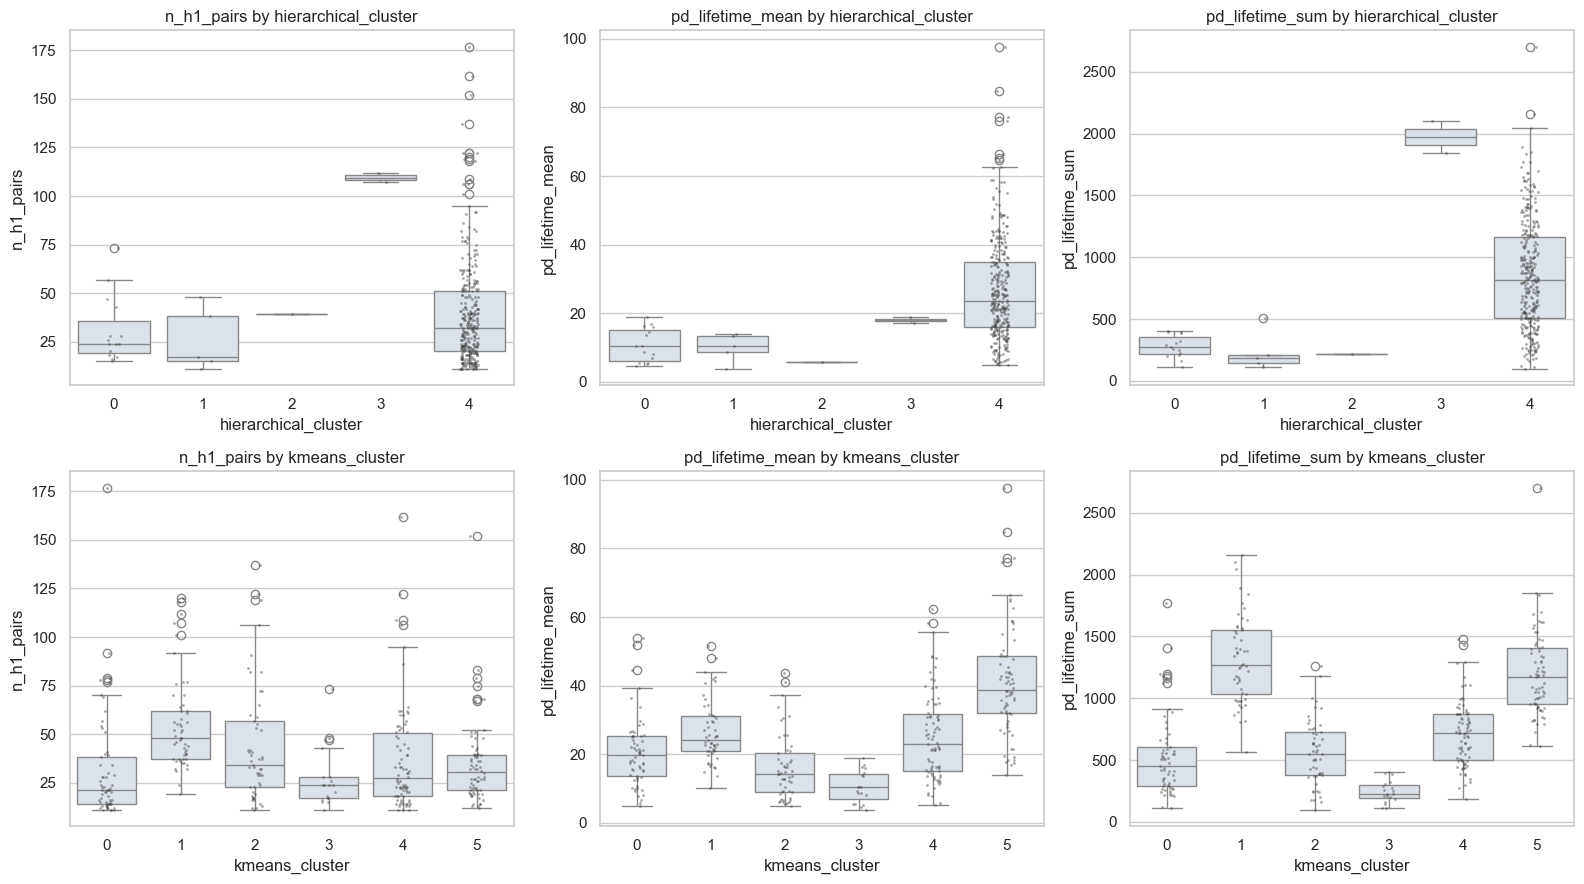

In [10]:
summary_cols = [
    'n_h1_pairs', 'x_max', 'pd_count', 'pd_lifetime_mean', 'pd_lifetime_std',
    'pd_lifetime_max', 'pd_lifetime_sum', 'pd_lifetime_q50', 'pd_lifetime_q75'
]

for cluster_col in ['hierarchical_cluster', 'kmeans_cluster']:
    print(cluster_col)
    cluster_summary = meta_features.groupby(cluster_col)[summary_cols].agg(['count', 'mean', 'median', 'std']).round(3)
    display(cluster_summary)

fig, axes = plt.subplots(2, 3, figsize=(16, 9))
for row, cluster_col in enumerate(['hierarchical_cluster', 'kmeans_cluster']):
    for ax, metric in zip(axes[row], ['n_h1_pairs', 'pd_lifetime_mean', 'pd_lifetime_sum']):
        sns.boxplot(data=meta_features, x=cluster_col, y=metric, ax=ax, color='#d9e2ec')
        sns.stripplot(data=meta_features, x=cluster_col, y=metric, ax=ax, color='0.25', size=2, alpha=0.45)
        ax.set_title(f'{metric} by {cluster_col}')
plt.tight_layout()
plt.show()


## 9. Medellin Polygon Maps


Map assignment status


,status,n_polygons
0,clustered,340
1,too_few_h1_pairs,167
2,missing_outputs,6


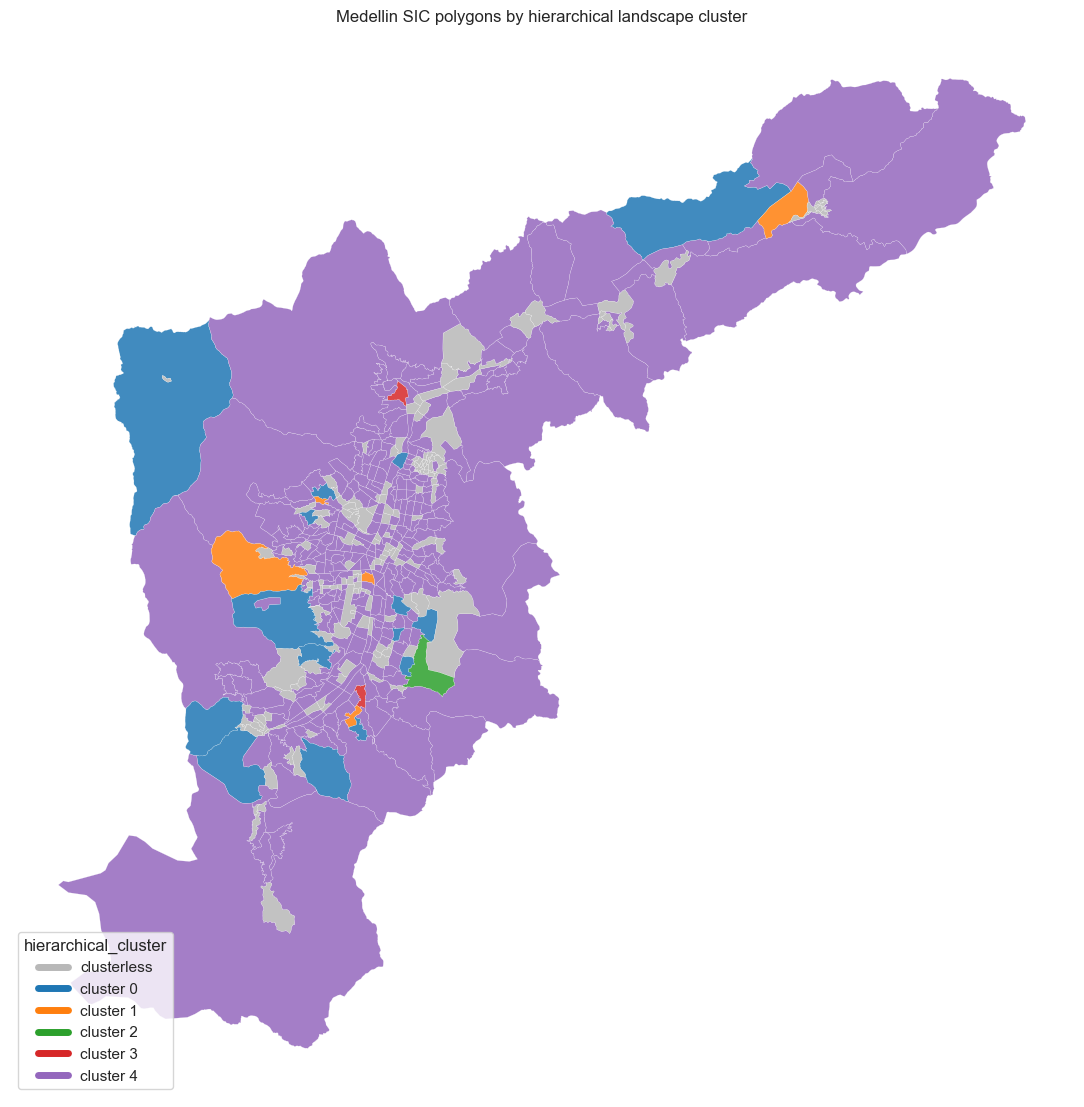

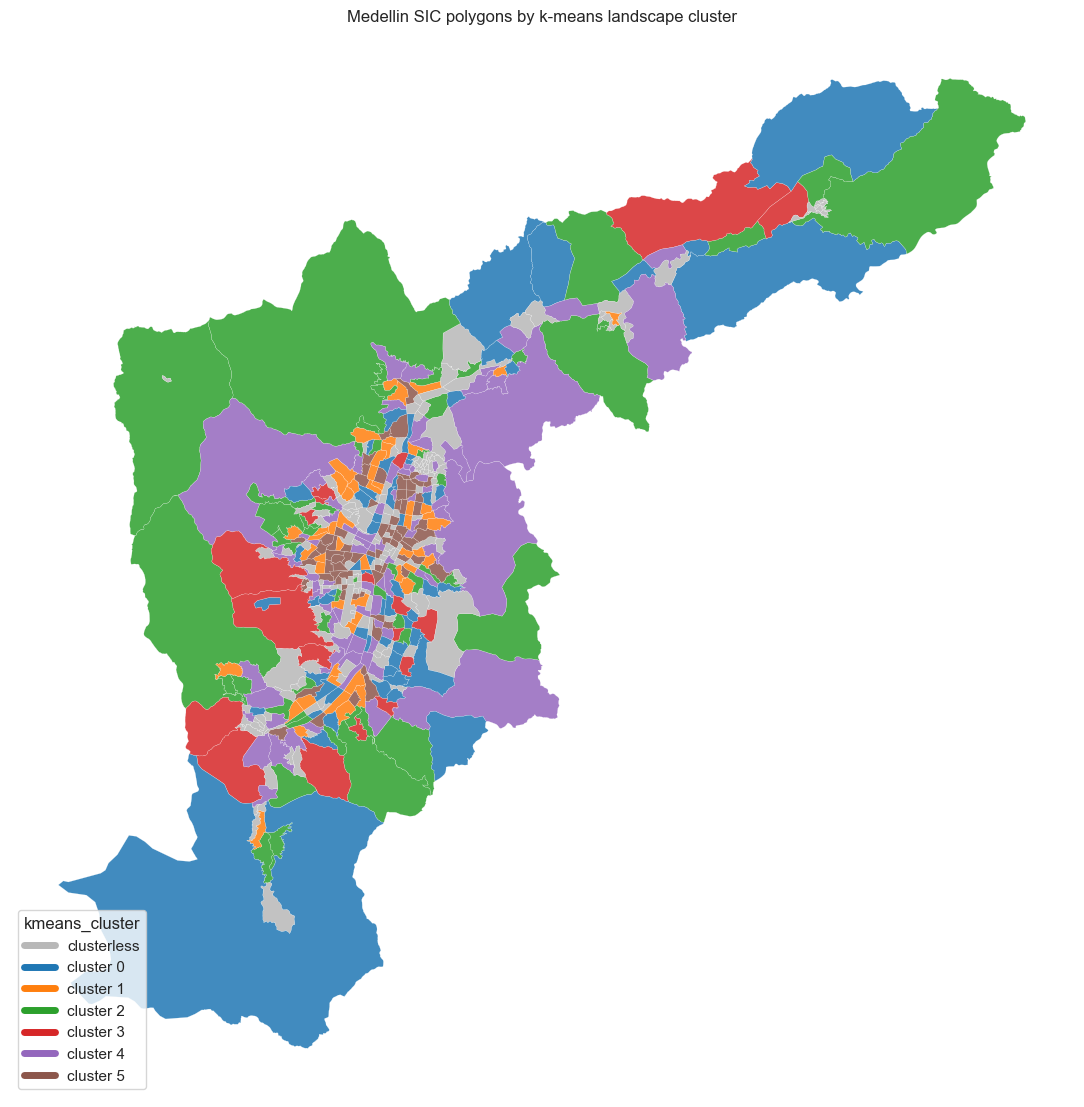

In [11]:
import geopandas as gpd
import osmnx as ox
from matplotlib.lines import Line2D

CLUSTERLESS_COLOR = '#b8b8b8'
CLUSTER_COLORS = (
    sns.color_palette('tab10', 10).as_hex()
    + sns.color_palette('Set2', 8).as_hex()
    + sns.color_palette('Dark2', 8).as_hex()
)

def cluster_color_map(labels) -> dict:
    unique = sorted(pd.Series(labels).dropna().astype(int).unique())
    return {label: CLUSTER_COLORS[i % len(CLUSTER_COLORS)] for i, label in enumerate(unique)}

def load_medellin_polygons() -> gpd.GeoDataFrame:
    gdf = gpd.read_file(SHAPEFILE).to_crs('EPSG:4326')
    gdf = gdf.reset_index().rename(columns={'index': 'source_row_index'})
    gdf['polygon_id'] = 'polygon_' + (gdf['source_row_index'] + 1).astype(str)
    gdf['sit_2017'] = gdf['SIT_2017'].astype(str)

    cluster_cols = [
        'source_row_index', 'n_h1_pairs', 'clusterless_reason',
        'hierarchical_cluster', 'kmeans_cluster'
    ]
    assignments = sample_status.merge(
        meta_features[['source_row_index', 'hierarchical_cluster', 'kmeans_cluster']],
        on='source_row_index', how='left'
    )
    return gdf.merge(assignments[cluster_cols], on='source_row_index', how='left')

def plot_polygon_cluster_map(polygons: gpd.GeoDataFrame, cluster_col: str, title: str):
    colors = cluster_color_map(polygons[cluster_col])
    plot_gdf = polygons.copy()
    plot_gdf['plot_color'] = plot_gdf[cluster_col].map(colors).fillna(CLUSTERLESS_COLOR)

    fig, ax = plt.subplots(figsize=(11, 13))
    plot_gdf.plot(ax=ax, color=plot_gdf['plot_color'], edgecolor='white', linewidth=0.15, alpha=0.85)
    ax.set_title(title)
    ax.set_axis_off()

    handles = [Line2D([0], [0], color=CLUSTERLESS_COLOR, lw=5, label='clusterless')]
    handles += [Line2D([0], [0], color=color, lw=5, label=f'cluster {label}') for label, color in colors.items()]
    ax.legend(handles=handles, loc='lower left', frameon=True, title=cluster_col)
    plt.tight_layout()
    plt.show()

medellin_polygons = load_medellin_polygons()
print('Map assignment status')
display(medellin_polygons['clusterless_reason'].fillna('missing_processed_output').value_counts().rename_axis('status').reset_index(name='n_polygons'))

plot_polygon_cluster_map(medellin_polygons, 'hierarchical_cluster', 'Medellin SIC polygons by hierarchical landscape cluster')
plot_polygon_cluster_map(medellin_polygons, 'kmeans_cluster', 'Medellin SIC polygons by k-means landscape cluster')


## 10. OSMnx Street Maps


Loading cached OSMnx edges from: /Users/gregorioperez/Documents/Maestria/Investigacion/levelset_urban/notebooks_clustering/clustering_medellin/medellin_sit_osmnx_drive_edges.geojson
OSMnx street edges: 72,496
PDF saved to: /Users/gregorioperez/Documents/Maestria/Investigacion/levelset_urban/notebooks_clustering/clustering_medellin/medellin_osmnx_hierarchical_clusters_landscape.pdf


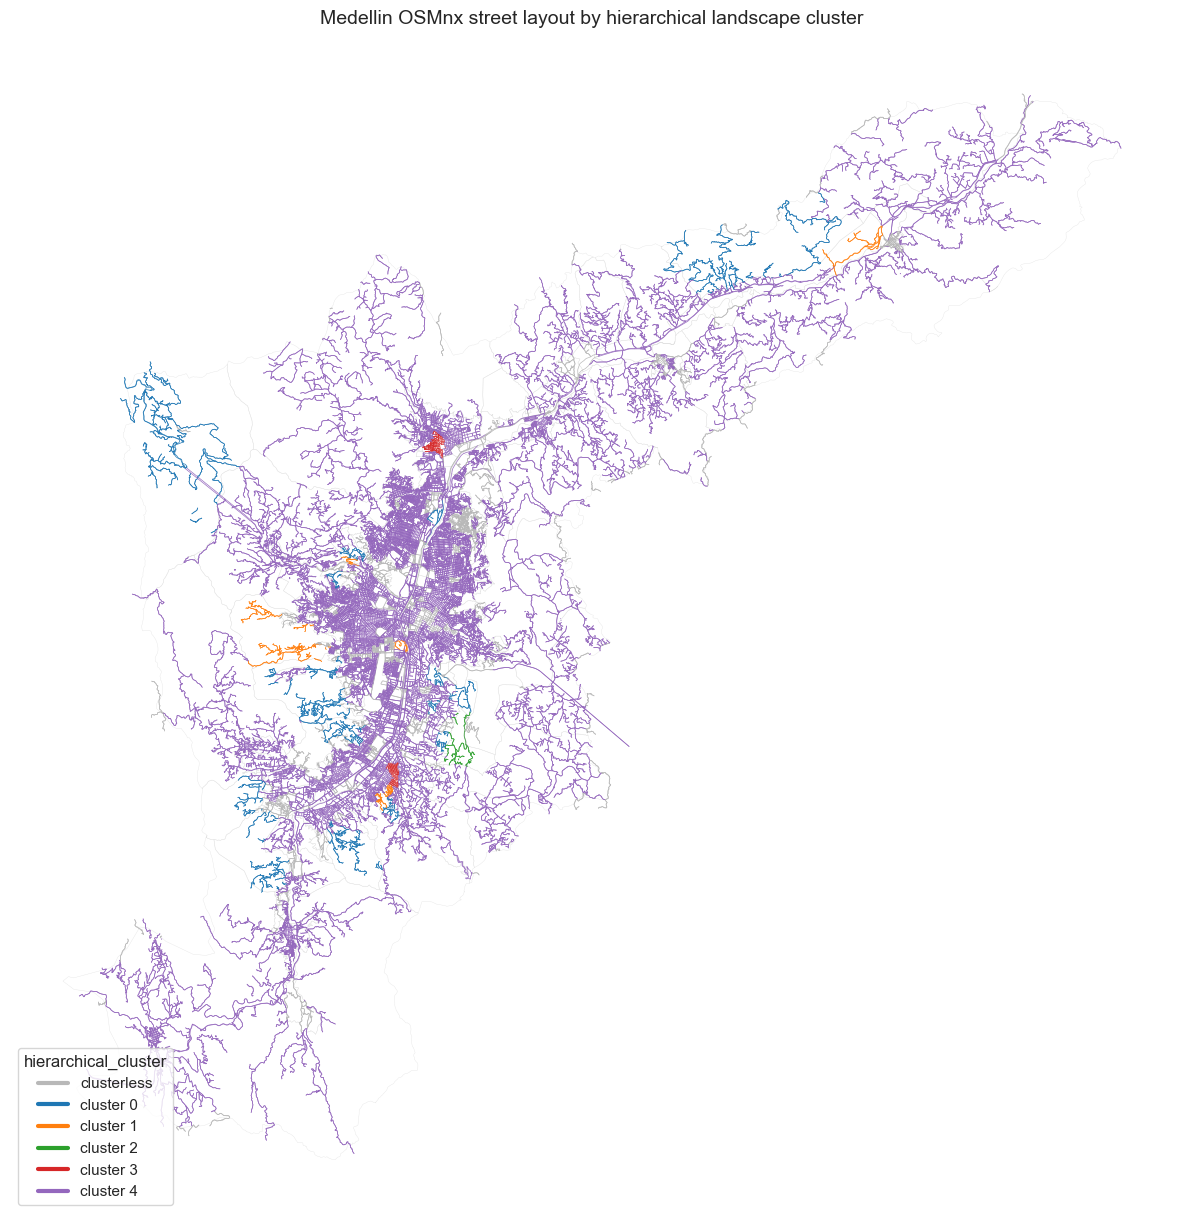

PDF saved to: /Users/gregorioperez/Documents/Maestria/Investigacion/levelset_urban/notebooks_clustering/clustering_medellin/medellin_osmnx_kmeans_clusters_landscape.pdf


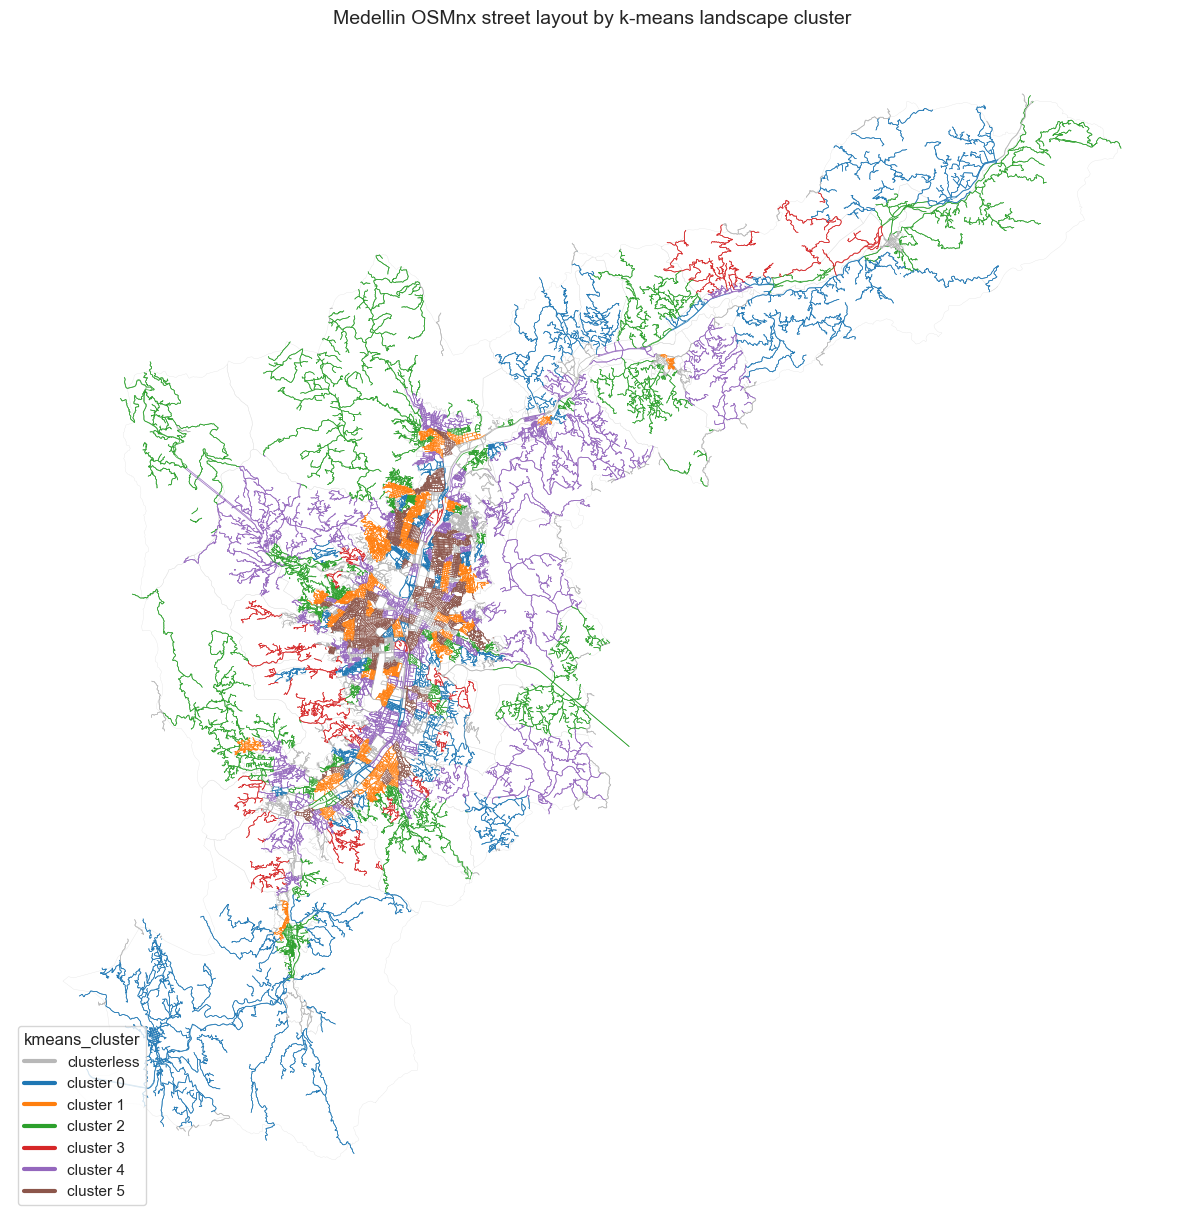

In [13]:
from pathlib import Path
from matplotlib.lines import Line2D

RUN_OSMNX_DOWNLOAD = True
OSMNX_NETWORK_TYPE = 'drive'
OSMNX_EDGES_CACHE = OUTPUT_DIR / 'medellin_sit_osmnx_drive_edges.geojson'

ox.settings.use_cache = True
ox.settings.cache_folder = str(OUTPUT_DIR / 'osmnx_cache')
ox.settings.log_console = False


def polygon_union(polygons: gpd.GeoDataFrame):
    if hasattr(polygons.geometry, 'union_all'):
        return polygons.geometry.union_all()

    return polygons.geometry.unary_union


def load_or_download_osmnx_edges(
    polygons: gpd.GeoDataFrame
) -> gpd.GeoDataFrame:

    if OSMNX_EDGES_CACHE.exists():
        print(f'Loading cached OSMnx edges from: {OSMNX_EDGES_CACHE}')

        return (
            gpd.read_file(OSMNX_EDGES_CACHE)
            .to_crs(polygons.crs)
        )

    if not RUN_OSMNX_DOWNLOAD:
        raise RuntimeError(
            f'{OSMNX_EDGES_CACHE} does not exist. '
            'Set RUN_OSMNX_DOWNLOAD=True to fetch it with OSMnx.'
        )

    boundary = polygon_union(polygons)

    G = ox.graph_from_polygon(
        boundary,
        network_type=OSMNX_NETWORK_TYPE,
        simplify=True,
        retain_all=True,
        truncate_by_edge=True,
    )

    edges = ox.graph_to_gdfs(
        G,
        nodes=False,
        edges=True,
        fill_edge_geometry=True,
    ).to_crs(polygons.crs)

    edges = (
        edges
        .reset_index(drop=True)[['geometry']]
        .copy()
    )

    OSMNX_EDGES_CACHE.parent.mkdir(
        parents=True,
        exist_ok=True,
    )

    edges.to_file(
        OSMNX_EDGES_CACHE,
        driver='GeoJSON',
    )

    print(f'OSMnx edges saved to: {OSMNX_EDGES_CACHE}')

    return edges


def attach_edge_clusters(
    edges: gpd.GeoDataFrame,
    polygons: gpd.GeoDataFrame,
    cluster_col: str,
) -> gpd.GeoDataFrame:

    edges_work = edges.reset_index(drop=True).copy()
    edges_work['edge_id'] = np.arange(len(edges_work))

    edge_points = edges_work[
        ['edge_id', 'geometry']
    ].copy()

    edge_points['geometry'] = (
        edge_points.geometry.representative_point()
    )

    join_cols = [
        'source_row_index',
        cluster_col,
        'geometry',
    ]

    joined = gpd.sjoin(
        edge_points,
        polygons[join_cols],
        how='left',
        predicate='within',
    )

    labels = (
        joined
        .drop_duplicates('edge_id')
        .set_index('edge_id')[cluster_col]
    )

    edges_work[cluster_col] = (
        edges_work['edge_id'].map(labels)
    )

    return edges_work


def plot_osmnx_street_cluster_map(
    edges: gpd.GeoDataFrame,
    polygons: gpd.GeoDataFrame,
    cluster_col: str,
    title: str,
    output_pdf: Path | str | None = None,
):
    street_clusters = attach_edge_clusters(
        edges=edges,
        polygons=polygons,
        cluster_col=cluster_col,
    )

    colors = cluster_color_map(
        polygons[cluster_col]
    )

    street_clusters['plot_color'] = (
        street_clusters[cluster_col]
        .map(colors)
        .fillna(CLUSTERLESS_COLOR)
    )

    fig, ax = plt.subplots(
        figsize=(12, 14)
    )

    polygons.boundary.plot(
        ax=ax,
        color='0.86',
        linewidth=0.25,
        alpha=0.8,
    )

    street_clusters.plot(
        ax=ax,
        color=street_clusters['plot_color'],
        linewidth=0.5,
        alpha=0.95,
    )

    ax.set_title(
        title,
        fontsize=14,
        pad=12,
    )

    ax.set_axis_off()

    handles = [
        Line2D(
            [0],
            [0],
            color=CLUSTERLESS_COLOR,
            lw=3,
            label='clusterless',
        )
    ]

    handles += [
        Line2D(
            [0],
            [0],
            color=color,
            lw=3,
            label=f'cluster {label}',
        )
        for label, color in colors.items()
    ]

    ax.legend(
        handles=handles,
        loc='lower left',
        frameon=True,
        title=cluster_col,
    )

    fig.tight_layout()

    if output_pdf is not None:
        output_pdf = Path(output_pdf)

        output_pdf.parent.mkdir(
            parents=True,
            exist_ok=True,
        )

        fig.savefig(
            output_pdf,
            format='pdf',
            bbox_inches='tight',
        )

        print(f'PDF saved to: {output_pdf}')

    plt.show()
    plt.close(fig)


try:
    street_edges = load_or_download_osmnx_edges(
        medellin_polygons
    )

    print(
        f'OSMnx street edges: {len(street_edges):,}'
    )

    plot_osmnx_street_cluster_map(
        edges=street_edges,
        polygons=medellin_polygons,
        cluster_col='hierarchical_cluster',
        title=(
            'Medellin OSMnx street layout by '
            'hierarchical landscape cluster'
        ),
        output_pdf=(
            OUTPUT_DIR
            / 'medellin_osmnx_hierarchical_clusters_landscape.pdf'
        ),
    )

    plot_osmnx_street_cluster_map(
        edges=street_edges,
        polygons=medellin_polygons,
        cluster_col='kmeans_cluster',
        title=(
            'Medellin OSMnx street layout by '
            'k-means landscape cluster'
        ),
        output_pdf=(
            OUTPUT_DIR
            / 'medellin_osmnx_kmeans_clusters_landscape.pdf'
        ),
    )

except Exception as exc:
    print(
        'OSMnx street map could not be built in this run.'
    )

    print(
        type(exc).__name__ + ':',
        exc,
    )

    print(
        'If this is an internet or Overpass issue, '
        'rerun this cell later. The polygon maps above '
        'do not need OSMnx.'
    )

## 11. Save Assignments


In [ ]:
ASSIGNMENTS_OUT = OUTPUT_DIR / 'cluster_medellin_sit_persistence_landscapes_pca_space_assignments.csv'
ALL_POLYGONS_OUT = OUTPUT_DIR / 'cluster_medellin_sit_persistence_landscapes_pca_space_all_polygons.csv'

output_cols = [
    'polygon_id', 'polygon_number', 'source_row_index', 'sit_2017', 'n_h1_pairs',
    'hierarchical_cluster', 'kmeans_cluster',
    'pd_lifetime_mean', 'pd_lifetime_max', 'pd_lifetime_sum',
    'pca1', 'pca2', 'tsne1', 'tsne2'
]

all_assignments = sample_status.merge(
    viz[['source_row_index', 'hierarchical_cluster', 'kmeans_cluster', 'pca1', 'pca2', 'tsne1', 'tsne2']],
    on='source_row_index', how='left', suffixes=('', '_clustered')
)

viz[output_cols].to_csv(ASSIGNMENTS_OUT, index=False)
all_assignments.to_csv(ALL_POLYGONS_OUT, index=False)

print(f'Wrote {ASSIGNMENTS_OUT}')
print(f'Wrote {ALL_POLYGONS_OUT}')
display(viz[output_cols].head())


## Notes

Cluster IDs are arbitrary and have no ground-truth urban-form interpretation here. Treat the hierarchical and k-means labels as exploratory summaries of the H1 persistence-landscape feature space.

Polygons with 10 or fewer H1 diagram points, missing outputs, failed outputs, or empty landscapes are excluded from clustering and appear as clusterless in the maps.
